# Final status: read this first

**The final traditional-track results use the 20,738-article EB-NeRD SMALL catalogue**, the group's rule from commit `57b3475`. They come from `Experiments/1.3_xgboost/rerun_small_catalogue.py`, run `20261105_small_seed42`. Older larger-pool runs must not be used in a SMALL-only comparison.

| Model | Selected setting | Recall@100 | Recall@200 | nDCG@100 | nDCG@200 | Recorded AUC |
|---|---|---|---|---|---|---|
| **XGBoost, final** | 31 leaves, 25 trees | 0.858 | 0.923 | 0.221 | 0.230 | 0.713 |
| LightGBM | 31 leaves, 75 trees | 0.828 | 0.907 | 0.217 | 0.228 | 0.718 |
| Logistic regression | C = 0.01 | 0.769 | 0.915 | 0.175 | 0.196 | 0.690 |

These are development results on all 29,110 validation requests. On the 28,910 requests not used for selection, XGBoost leads LightGBM by +0.031 Recall@100 (95% CI +0.028 to +0.033). XGBoost test predictions cover all 29,142 holdout requests; test labels were not loaded and no test metric is reported. In 65.2% of XGBoost validation requests, scores tie at rank 200.

XGBoost is the track's final model. Its selected setting was the same on the larger and SMALL catalogues.

**The cells below are the record of the earlier larger-pool development run.** Their saved outputs and paths were not rerun, and their numbers are not the final results. To reproduce the final run in Colab, mount Drive and run `python rerun_small_catalogue.py` from `Experiments/1.3_xgboost`. Paths are set in `project_paths.py`.

# 1. Business hypothesis and experiment overview

| Item | Value |
|---|---|
| Experiment ID | `1.3_xgboost` (traditional models track) |
| Owner | Nigel Yap |
| Model | XGBoost gradient-boosted trees (binary click objective) |
| Scope | Development comparison with `1.1_lightgbm_ranker`: 200 selection requests and 3,000 evaluation requests from validation, each against the full eligible catalogue |

**Business objective addressed.** *Relevant recommendations*: Stage 1 must keep the articles a reader would click inside the shortlist that the reranker receives.

**Hypothesis.** XGBoost uses the same family of method as LightGBM, so a large difference is not expected. A clear win would justify replacing LightGBM; a tie would mean the simpler existing model is sufficient.

**Design.** The inputs are the same 200 features used by 1.1 (the slate-dependent features remain removed). Training uses recorded slates only, unshown articles are never labelled, and catalogue features are rebuilt with `1.1_lightgbm_ranker/catalogue_v4.py`. The bounded search is selected by known-click Recall@100 on the same 200 validation requests as 1.1, then nDCG@100, then the earlier trial. Test is not loaded, so its labels stay unread.

# 2. Setup and run configuration

In [1]:
import os, sys, json, time, pickle, shutil, platform, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent / "1.1_lightgbm_ranker"))
import catalogue_v4 as cv
warnings.filterwarnings("ignore", category=FutureWarning)

EXPERIMENT_ID = "1.3_xgboost"; OWNER = "Nigel Yap"; SEED = REQUEST_SEED = 42
RUN_ID = os.environ.get("BT4222_RUN_ID", "20261104_val3000_seed42")
DEV_FRAC = float(os.environ.get("BT4222_DEV_FRAC", "0"))
SELECTION_N = int(os.environ.get("BT4222_SEL_N", "200")); EVAL_N = int(os.environ.get("BT4222_EVAL_N", "3000"))
ROUNDS = int(os.environ.get("BT4222_ROUNDS", "400")); THREADS = int(os.environ.get("BT4222_THREADS", "14"))
SELECTION_K, EXPORT_K = 100, 200
SHARED = Path(os.environ.get("BT4222_SHARED", r"C:\Users\nigel\BT4222 Shared Final Folder"))
FEATURE_ROOT = SHARED / "feature_engineering_nov4"; SMALL = Path(r"C:\Users\nigel\bt4222-data\ebnerd_small")
TEST_ARTICLES = Path(r"C:\Users\nigel\OneDrive\Desktop\BT4222 Final\ebnerd_large\articles.parquet")
LGBM_RUN = Path.cwd().parent / "1.1_lightgbm_ranker" / "outputs" / "20261104_v4_union_fullval_seed42"
OUT = Path("outputs") / RUN_ID; PERSIST = Path(os.environ.get("BT4222_PERSIST_DIR", str(SHARED / "Experiments" / EXPERIMENT_ID / RUN_ID)))
for d in ["predictions/validation", "rankings/validation", "diagnostics/recorded_slates", "model", "tuning"]: (OUT / d).mkdir(parents=True, exist_ok=True)
def log(m):
    line = time.strftime("%H:%M:%S ") + m; print(line, flush=True)
    with open(OUT / "progress.log", "a", encoding="utf-8") as f: f.write(line + "\n")
log(f"start {RUN_ID} | selection {SELECTION_N} | evaluation {EVAL_N}")

16:45:14 start 20261104_val3000_seed42 | selection 200 | evaluation 3000


**Protocol.** Selection and evaluation requests are prefixes of the shared blake2b hash order, so they are identical to the requests used by 1.1. Validation is used for selection, so every score here is a **development result**. The 3,000 evaluation requests include the 200 selection requests.

# 3. Load and check shared data

In [2]:
state = json.load(open(FEATURE_ROOT / "feature_vocabulary.json", encoding="utf-8"))
FEATURES = json.load(open(LGBM_RUN / "model" / "model_config.json", encoding="utf-8"))["feature_names"]
assert not set(FEATURES) & set(cv.POOL_DEPENDENT) and len(FEATURES) == 200
data = {}
keys = ["user_id", "impression_id", "candidate_article_id", "impression_time"]
for sp in ["train", "validation"]:
    df = pd.read_parquet(FEATURE_ROOT / f"{sp}_features.parquet", columns=list(dict.fromkeys(keys + FEATURES + ["clicked"])))
    assert not df.duplicated(keys[:3]).any()
    df["behaviour_id"] = df.user_id.astype("int64").astype(str) + ":" + df.impression_id.astype("int64").astype(str)
    if DEV_FRAC > 0 and sp == "train":
        ids = df.behaviour_id.unique(); keep = set(np.random.default_rng(SEED).choice(ids, int(len(ids) * DEV_FRAC), replace=False)); df = df[df.behaviour_id.isin(keep)]
    df["g"] = pd.factorize(df.behaviour_id)[0]; data[sp] = df.sort_values("g", kind="stable").reset_index(drop=True)
    print(f"{sp}: rows {len(df):,} | requests {df.g.nunique():,} | click rate {df.clicked.mean():.4f}")
cat = cv.Catalogue([SMALL / "articles.parquet", TEST_ARTICLES], state)
assert cat.fingerprint == "cb89570c1bc70654", "catalogue differs from 1.1"
first = data["validation"].drop_duplicates("behaviour_id").set_index("behaviour_id")
reqs = cv.hash_order(first.reset_index()[["user_id", "impression_id"]], "validation", REQUEST_SEED)
known = data["validation"][data["validation"].clicked == 1].groupby("behaviour_id").candidate_article_id.apply(lambda s: set(s.astype("int64")))
reqs["known"] = reqs.behaviour_id.map(known).map(lambda s: s if isinstance(s, set) else set())
SEL, EVAL = reqs.head(SELECTION_N), reqs.head(EVAL_N)
ref = pd.read_parquet(LGBM_RUN / "predictions/validation/request_manifest.parquet", columns=["behaviour_id"]).head(EVAL_N)
assert ref.behaviour_id.tolist() == EVAL.behaviour_id.tolist(), "requests differ from 1.1"
PROFILES = cv.build_profiles(SMALL / "validation" / "history.parquet", EVAL.user_id.unique(), cat, state)
print(f"catalogue {cat.n:,} articles | selection {len(SEL)} | evaluation {len(EVAL)} | request order identical to 1.1")
def features_for(b, ix):
    r = first.loc[b]; sub = r.is_subscriber
    c = {"impression_time": r.impression_time.to_datetime64(), "is_sso_user": float(r.is_sso_user) if pd.notna(r.is_sso_user) else np.nan, "is_subscriber": bool(sub) if pd.notna(sub) else float("nan"),
         "is_front_page": float(r.is_front_page), "hour": float(r.hour), "day_of_week": float(r.day_of_week)}
    c.update({k: float(r[k]) for k in r.index if k.startswith("ohe_device_type_")})
    return cv.request_features(cat, PROFILES[int(r.user_id)], c, ix, FEATURES)
bad = 0; rows = 0
for b in SEL.behaviour_id.head(50):
    rec = data["validation"][data["validation"].behaviour_id == b]; ix = cat.pos.reindex(rec.candidate_article_id.to_numpy()).to_numpy().astype(int)
    bad += len(cv.compare_to_shared(rec[FEATURES], features_for(b, ix), FEATURES)); rows += len(rec)
print(f"feature rebuild check on {rows} shared rows: {bad} mismatched columns"); assert bad == 0

train: rows 2,585,747 | requests 232,887 | click rate 0.0904


validation: rows 344,666 | requests 29,110 | click rate 0.0849


catalogue 125,541 articles | selection 200 | evaluation 3000 | request order identical to 1.1


feature rebuild check on 437 shared rows: 0 mismatched columns


# 4. Prepare model inputs

In [3]:
# Trees use raw values and handle missing values natively, as in 1.1. No transform is fitted.
import xgboost as xgb
PREPROCESSING = dict(features=FEATURES, imputation="none (XGBoost native missing handling)", scaling="none")
dtrain = xgb.DMatrix(data["train"][FEATURES].to_numpy("float32"), label=data["train"].clicked.to_numpy(), missing=np.nan, nthread=THREADS)
print(dtrain.num_row(), dtrain.num_col())

2585747 200


In [4]:
def evaluate(specs, requests):
    out = {k: [] for k in specs}; ties = dict.fromkeys(specs, 0)
    for n, r in enumerate(requests.itertuples(), 1):
        ix = cat.eligible(first.loc[r.behaviour_id].impression_time.to_datetime64()); ids = cat.ids[ix]; M_ = features_for(r.behaviour_id, ix)
        for k, fn in specs.items():
            sc = fn(M_); order, cross = cv.top_k(sc, ids, EXPORT_K); ties[k] += int(cross); out[k].append(cv.retrieval_metrics(ids[order], r.known, (100, 200)))
        if n % 50 == 0: log(f"selection: {n}/{len(requests)} requests")
    return {k: {**pd.DataFrame(v).mean().to_dict(), "ties_at_cutoff": ties[k], "requests": len(v)} for k, v in out.items()}

# 5. Define and train model

In [5]:
ROUND_CHECK = sorted(({*range(25, 201, 25), 300, ROUNDS}) & set(range(1, ROUNDS + 1)))
BASE = dict(objective="binary:logistic", tree_method="hist", grow_policy="lossguide", max_depth=0, eta=0.08, subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
            max_bin=127, min_child_weight=5, seed=SEED, nthread=THREADS, eval_metric="logloss")
TRIALS = {"leaves31": 31, "leaves63": 63, "leaves127": 127}; models = {}
for n, l in TRIALS.items():
    t0 = time.time(); models[n] = xgb.train({**BASE, "max_leaves": l}, dtrain, ROUNDS); log(f"{n}: trained {ROUNDS} trees in {time.time()-t0:.0f}s")
mk = lambda b, k: (lambda M_: b.inplace_predict(M_, iteration_range=(0, k), predict_type="margin", missing=np.nan))
RES = evaluate({(n, k): mk(b, k) for n, b in models.items() for k in ROUND_CHECK}, SEL)
trials = pd.DataFrame([dict(trial=n, checkpoint=k, **v) for (n, k), v in RES.items()]); trials.to_csv(OUT / "tuning" / "trials.csv", index=False)
win = trials.assign(_o=trials.trial.map({n: i for i, n in enumerate(TRIALS)})).sort_values(["recall@100", "ndcg@100", "_o", "checkpoint"], ascending=[False, False, True, True]).iloc[0]
CHOSEN, BEST = win.trial, int(win.checkpoint); model = models[CHOSEN]; score = mk(model, BEST)
model[:BEST].save_model(str(OUT / "model" / "model.json")); MODEL_DESC = dict(library="xgboost", max_leaves=TRIALS[CHOSEN], trees=BEST, file="model.json")
log(f"SELECTED {CHOSEN}, {BEST} trees Recall@100={win['recall@100']:.4f} nDCG@100={win['ndcg@100']:.4f}")
trials.sort_values(["recall@100", "ndcg@100"], ascending=False).head(8).round(4)

16:46:49 leaves31: trained 400 trees in 75s


16:48:05 leaves63: trained 400 trees in 76s


16:49:35 leaves127: trained 400 trees in 90s


16:52:08 selection: 50/200 requests


16:54:40 selection: 100/200 requests


16:57:12 selection: 150/200 requests


16:59:44 selection: 200/200 requests


16:59:44 SELECTED leaves31, 25 trees Recall@100=0.8150 nDCG@100=0.2208


,trial,checkpoint,recall@100,ndcg@100,recall@200,ndcg@200,ties_at_cutoff,requests
0,leaves31,25,0.815,0.2208,0.915,0.2350,141,200
2,leaves31,75,0.785,0.2214,0.905,0.2384,78,200
15,leaves63,150,0.780,0.2236,0.835,0.2313,61,200
20,leaves127,25,0.780,0.2125,0.895,0.2287,124,200
1,leaves31,50,0.775,0.2149,0.905,0.2335,96,200
21,leaves127,50,0.770,0.2105,0.850,0.2218,92,200
10,leaves63,25,0.770,0.2100,0.915,0.2304,122,200
14,leaves63,125,0.765,0.2227,0.840,0.2334,72,200


# 6. Validation results

In [6]:
def auc_nd(g, y, s, k=5):
    d = pd.DataFrame({"g": g, "y": y.astype(float), "s": s}); d["r"] = d.groupby("g", sort=False)["s"].rank(method="average")
    a = d.assign(ry=d.r * d.y).groupby("g", sort=False).agg(n=("y", "size"), p=("y", "sum"), ry=("ry", "sum")); q = a.n - a.p; ok = (a.p > 0) & (q > 0)
    auc = ((a.ry - a.p * (a.p + 1) / 2) / (a.p * q))[ok].mean()
    d["ty"] = d.groupby(["g", "s"], sort=False)["y"].transform("mean"); d = d.sort_values(["g", "s"], ascending=[True, False], kind="stable"); d["pos"] = d.groupby("g", sort=False).cumcount() + 1
    dcg = (d.ty / np.log2(d.pos + 1)).where(d.pos <= k, 0).groupby(d.g, sort=False).sum(); disc = np.r_[0, np.cumsum(1 / np.log2(np.arange(1, k + 1) + 1))]; ideal = pd.Series(disc[np.minimum(a.p.to_numpy(), k).astype(int)], index=a.index)
    return float(auc), float((dcg / ideal).mean())
v = data["validation"]; sv = score(v[FEATURES].to_numpy("float32")); AUC, ND5 = auc_nd(v.g.to_numpy(), v.clicked.to_numpy(), sv); print(f"recorded-slate diagnostic (all validation rows): AUC {AUC:.4f}, nDCG@5 {ND5:.4f}")

recorded-slate diagnostic (all validation rows): AUC 0.7130, nDCG@5 0.5459


mean |SHAP| share on 20,000 recorded validation rows: freshness 40.6% | personalisation 31.4%


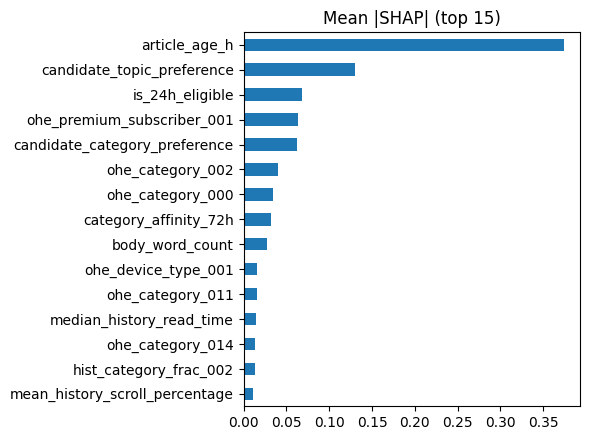

In [7]:
rng = np.random.default_rng(SEED); s_ = rng.choice(len(v), min(20000, len(v)), replace=False); dm = xgb.DMatrix(v[FEATURES].iloc[s_].to_numpy("float32"), missing=np.nan, nthread=THREADS)
sh = model.predict(dm, iteration_range=(0, BEST), pred_contribs=True)[:, :-1]; mean_abs = pd.Series(np.abs(sh).mean(axis=0), index=FEATURES).sort_values(ascending=False); mean_abs.to_csv(OUT / "tuning" / "mean_abs_shap.csv", header=["mean_abs_shap"])
fresh = ["article_age_h", "article_age_missing", "is_24h_eligible"]; pers = [c for c in FEATURES if c.startswith(("hist_", "candidate_", "category_affinity", "last5_mean_topic", "topic_affinity", "has_any_topic_overlap", "same_category_"))]
share = mean_abs / mean_abs.sum(); print("mean |SHAP| share on 20,000 recorded validation rows: freshness %.1f%% | personalisation %.1f%%" % (100 * share[fresh].sum(), 100 * share[pers].sum()))
mean_abs.head(15).iloc[::-1].plot.barh(figsize=(6, 4.5), title="Mean |SHAP| (top 15)"); plt.tight_layout(); plt.show()

**Reading the evidence (development results).**

- **Selected setting.** `max_leaves = 31`, 25 trees: Recall@100 = 0.815, nDCG@100 = 0.221 on the 200 selection requests. As with LightGBM, more trees made shortlisting worse: `leaves31` falls to 0.680 at 400 trees. 25 was the smallest checkpoint tried, so fewer trees were not tested.
- **Compared with LightGBM on the 3,000 evaluation requests.** XGBoost has Recall@100 = 0.800 against 0.773.
- **SHAP.** On 20,000 recorded validation rows, freshness columns hold 40.6% of mean absolute SHAP and history-based personalisation columns hold 31.4%. `article_age_h` is the largest single feature, followed by `candidate_topic_preference`. This shows what the model uses, not what causes clicks, and it is measured on shown slates rather than the whole catalogue.
- **Ties.** With only 25 trees, many articles share a score. On 500 non-selection requests, Recall@100 and Recall@200 did not change under ascending, descending or random tie-breaking, so ties are not producing the lead over LightGBM.

# 7. Predict and export

In [8]:
t0 = time.time(); bids, ia, sa, man = [], [], [], []
for i, r in enumerate(EVAL.itertuples(), 1):
    ix = cat.eligible(first.loc[r.behaviour_id].impression_time.to_datetime64()); ids = cat.ids[ix]; sc = score(features_for(r.behaviour_id, ix)); order, cross = cv.top_k(sc, ids, EXPORT_K); top = ids[order].astype("int64")
    bids.append(r.behaviour_id); ia.append(top); sa.append(np.asarray(sc[order], "float64")); man.append(dict(behaviour_id=r.behaviour_id, eligible_pool=len(ix), shortlist_len=len(top), known_clicks=len(r.known), known_clicks_eligible=len(r.known & set(ids)), tie_at_cutoff=bool(cross), **cv.retrieval_metrics(top, r.known, (100, 200))))
    if i % 500 == 0: log(f"export: {i}/{len(EVAL)} requests")
sig = lambda x: 1 / (1 + np.exp(-x)); lens = [len(x) for x in ia]
S = pd.DataFrame({"behaviour_id": np.repeat(np.array(bids, dtype=object), lens), "article_id": np.concatenate(ia), "rank": np.concatenate([np.arange(1, n + 1) for n in lens]), "score": np.concatenate(sa)}); S["click_probability"] = sig(S.score.to_numpy())
S.to_parquet(OUT / "predictions/validation/submission_article_scores.parquet", index=False, compression="zstd")
pd.DataFrame({"behaviour_id": bids, "article_ids": [x.tolist() for x in ia]}).to_parquet(OUT / "rankings/validation/submission_top_200.parquet", index=False, compression="zstd")
man = pd.DataFrame(man); man.to_parquet(OUT / "predictions/validation/request_manifest.parquet", index=False)
pd.DataFrame({"behaviour_id": v.behaviour_id, "article_id": v.candidate_article_id.astype("int64"), "score": sv, "click_probability": sig(sv)}).sort_values(["behaviour_id", "article_id"]).to_parquet(OUT / "diagnostics/recorded_slates/validation_scores.parquet", index=False, compression="zstd")
R2 = pd.read_parquet(OUT / "rankings/validation/submission_top_200.parquet"); S2 = pd.read_parquet(OUT / "predictions/validation/submission_article_scores.parquet")
assert len(R2) == len(EVAL) and R2.behaviour_id.is_unique and (R2.article_ids.map(len) == 200).all() and np.array_equal(np.concatenate(R2.article_ids.map(lambda x: np.asarray(x, "int64")).to_list()), S2.article_id.to_numpy()) and np.isfinite(S2.score).all()
metrics = {c: float(man[c].mean()) for c in ("recall@100", "ndcg@100", "recall@200", "ndcg@200")}; log(f"evaluation metrics {metrics} ({time.time()-t0:.0f}s)")
L1 = pd.read_parquet(LGBM_RUN / "predictions/validation/request_manifest.parquet"); lstm = pd.read_parquet(SHARED / "catalogue" / "lstm_per_request.parquet")
J = man.merge(L1, on="behaviour_id", suffixes=("", "_lgbm")).merge(lstm, on="behaviour_id"); rows = []
for k, q in (("recall@100", "known_click_recall@100"), ("ndcg@100", "observed_click_ndcg@100"), ("recall@200", "known_click_recall@200"), ("ndcg@200", "observed_click_ndcg@200")):
    for name, col in (("LightGBM", k + "_lgbm"), ("LSTM", q)):
        d = (J[k] - J[col]).to_numpy("float64"); se = d.std(ddof=1) / np.sqrt(len(J)); rows.append(dict(metric=k, compared_with=name, this_model=J[k].mean(), other=J[col].mean(), difference=d.mean(), ci_low=d.mean() - 1.96 * se, ci_high=d.mean() + 1.96 * se))
cmp_ = pd.DataFrame(rows); cmp_.to_csv(OUT / "tuning" / "paired_comparison_3000.csv", index=False); cmp_.round(4)

17:01:00 export: 500/3000 requests


17:02:13 export: 1000/3000 requests


17:03:26 export: 1500/3000 requests


17:04:39 export: 2000/3000 requests


17:05:52 export: 2500/3000 requests


17:07:06 export: 3000/3000 requests


17:07:06 evaluation metrics {'recall@100': 0.80045, 'ndcg@100': 0.20925240174493615, 'recall@200': 0.9019333333333334, 'ndcg@200': 0.22371054814046795} (441s)


,metric,compared_with,this_model,other,difference,ci_low,ci_high
0,recall@100,LightGBM,0.8004,0.7732,0.0272,0.0187,0.0358
1,recall@100,LSTM,0.8004,0.7161,0.0844,0.0688,0.1000
2,ndcg@100,LightGBM,0.2093,0.2058,0.0035,-0.0001,0.0070
3,ndcg@100,LSTM,0.2093,0.1943,0.0150,0.0081,0.0219
4,recall@200,LightGBM,0.9019,0.8906,0.0113,0.0053,0.0174
5,recall@200,LSTM,0.9019,0.8523,0.0496,0.0379,0.0614
6,ndcg@200,LightGBM,0.2237,0.2225,0.0012,-0.0021,0.0046
7,ndcg@200,LSTM,0.2237,0.2135,0.0102,0.0037,0.0167


In [9]:
PR = OUT / "model" / "preprocessing.pkl"; pickle.dump(PREPROCESSING, open(PR, "wb"))
shutil.copy(Path.cwd().parent / "1.1_lightgbm_ranker" / "catalogue_v4.py", OUT / "model" / "catalogue_v4.py")
git = lambda *x: subprocess.run(["git", *x], capture_output=True, text=True).stdout.strip()
pk = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__)
if "xgb" == "lr":
    import sklearn; pk["scikit-learn"] = sklearn.__version__
else: pk["xgboost"] = xgb.__version__
cfg = dict(experiment_id=EXPERIMENT_ID, run_id=RUN_ID, owner=OWNER, seed=SEED, request_sampling_seed=REQUEST_SEED, export_schema_version=4, prediction_pool="time_eligible_catalogue", selection_k=SELECTION_K, export_k=EXPORT_K,
    scope=dict(selection_requests=len(SEL), evaluation_requests=len(EVAL), split="validation", sampled_run=True, train_and_test_exported=False, training="all recorded train rows" if DEV_FRAC == 0 else f"DEV {DEV_FRAC}"),
    eligibility=dict(policy=cv.POLICY, catalogue_articles=cat.n, catalogue_fingerprint=cat.fingerprint, shared_catalogue_id_fingerprint_sha256="46bc36568a9bc1c6fdcfd101079b2cfef6f4192f4505032766fc858490c5f877"),
    selection=dict(primary="mean known-click Recall@100", secondary="mean observed-click nDCG@100", tie_rule="then earlier trial/checkpoint", selected=str(CHOSEN), trials=list(TRIALS)), model=MODEL_DESC,
    score_semantics=dict(score_type="logit", click_probability="sigmoid(score), uncalibrated"), features=FEATURES, packages=pk, code_commit=git("rev-parse", "HEAD"), uncommitted_changes=bool(git("status", "--porcelain")), persistent_artifact_location=str(PERSIST))
(OUT / "run_config.json").write_text(json.dumps(cfg, indent=2, default=str))
(OUT / "metrics.json").write_text(json.dumps(dict(note="development results; 3,000 validation requests include the 200 selection requests", evaluation=metrics, recorded_slate_diagnostic=dict(auc=AUC, ndcg5=ND5), selected_selection=dict(recall100=float(win["recall@100"]), ndcg100=float(win["ndcg@100"]))), indent=2))
(OUT / "requirements.txt").write_text("\n".join(f"{k}=={v}" for k, v in pk.items() if k != "python") + "\npyarrow\nscipy\nmatplotlib\n")

67

# 8. Reload check

In [10]:
shutil.copytree(OUT, PERSIST, dirs_exist_ok=True)
if "xgb" == "lr":
    rm = pickle.load(open(PERSIST / "model" / "model.pkl", "rb")); pr = pickle.load(open(PERSIST / "model" / "preprocessing.pkl", "rb"))
    def re_score(M_):
        X = np.array(M_, "float32"); idx = [FEATURES.index(c) for c in pr["log1p_features"]]; X[:, idx] = np.log1p(np.maximum(X[:, idx], 0)); m = np.isnan(X); X[m] = np.take(pr["median"], np.where(m)[1]); return ((X - pr["mean"]) / pr["std"]).astype("float32") @ rm.coef_[0] + rm.intercept_[0]
else:
    rb = xgb.Booster(); rb.load_model(str(PERSIST / "model" / "model.json")); re_score = lambda M_: rb.inplace_predict(M_, predict_type="margin", missing=np.nan)
ex = pd.read_parquet(PERSIST / "predictions/validation/submission_article_scores.parquet"); worst = 0.0
for b in EVAL.behaviour_id.head(5):
    ix = cat.eligible(first.loc[b].impression_time.to_datetime64()); r_ = ex[ex.behaviour_id == b].set_index("article_id").score
    worst = max(worst, float(np.abs(pd.Series(re_score(features_for(b, ix)), index=cat.ids[ix]).reindex(r_.index).to_numpy() - r_.to_numpy()).max()))
print(f"max abs difference {worst:.2e}"); assert worst < 1e-5; log("RELOAD CHECK PASSED")

max abs difference 0.00e+00
17:07:09 RELOAD CHECK PASSED


# 9. Business interpretation and handoff

**Finding.** XGBoost is this track's final model. On all 29,110 validation requests (`20261104_fullval_seed42`) it gets Recall@100 = 0.809, Recall@200 = 0.908, nDCG@100 = 0.212 and nDCG@200 = 0.226, against 0.781, 0.896, 0.207 and 0.224 for LightGBM on the same requests. On the 28,910 requests not used for selection, the Recall@100 lead is +0.029 (95% CI +0.026 to +0.031). These are development results.

**Relation to the business objective.** It keeps more known clicks for the reranker: 90.9% of known validation clicks are in the top 200, while 9.1% (2,675 of 29,249) are lost before Stage 2. Offline clicks are an engagement proxy and do not show retention.

**Limitations.** Selection used 200 validation requests, and 25 trees was the smallest option tried. 69.2% of requests have tied scores at rank 200. This bundle has no train or test catalogue export, and the recorded-slate AUC (0.713) is slightly below LightGBM's (0.718). The comparison does not include later LSTM, HUIM or pretrained runs, which the shared evaluation must cover.

**Handoff.** The full validation bundle is `Experiments/1.3_xgboost/20261104_fullval_seed42`, created by `export_full_validation.py` from this notebook's saved model without retraining. It includes top-200 scores and rankings, full recorded-slate scores, the model and `run_config.json`.